# 量子計算の実行例

この章では、身近な問題を1つ取り上げて量子計算で答えを導いてみましょう。

## 販促セールの日程決め

Z市には6つの区域があり、各区域にコンビニが1店ずつあります。販促セールを「前半」と「後半」の2回に分けて行うことになり、各店をどちらかの日程に割り当てます。

隣り合う区域の店が同じ日程でセールをすると、客を取り合い、セールの効果が下がります。そのため、隣り合う区域は、なるべく別の日程にしたいと考えます。ただし、隣り合う組のすべてを別の日程にできるとは限りません。そこで、組ごとに、客層がどれだけ重なっているかを数値で置き、この数値が大きい組ほど、別の日程にすることを優先します。この数値を、組の**重み**と呼びます。

図の線が隣り合う区域の組、線の数字が組の重みです。

![6つの区域 A から F と、隣り合う区域を結ぶ9本の線。線の数字は組の重み(客層の重なりの大きさ)](./resources/ch04-districts.svg)

セールの日程は、**別の日程になった組の重みの合計**が大きいほど重なる客層の店舗間で顧客の奪い合いが発生しないため、よい日程組みと考えることができます。
この合計が最も大きい割り当てを求めることが、この題材の目標です。以降、単に「重みの合計」と書いたときは、別の日程になった組の重みの合計を指します。

区域と組を、Python のデータとして定義します。以降のすべてのコードで、このデータを使います。

In [1]:
DISTRICTS = ["A", "B", "C", "D", "E", "F"]

# (区域, 区域, 重み)。重みは客層の重なりの大きさで、この教材で置いた仮定値
NEIGHBORS = [
    ("A", "B", 3), ("B", "C", 4), ("D", "E", 2), ("E", "F", 3),
    ("A", "D", 2), ("B", "E", 1), ("C", "F", 2), ("B", "D", 3), ("C", "E", 1),
]

# 区域を番号(A=0, B=1, ...)に直した組
EDGES = [(DISTRICTS.index(a), DISTRICTS.index(b), w) for a, b, w in NEIGHBORS]
N_DISTRICTS = len(DISTRICTS)
TOTAL_WEIGHT = sum(w for _, _, w in EDGES)  # すべての組の重み
print(f"区域の数: {N_DISTRICTS}、隣り合う組の数: {len(EDGES)}、すべての組の重み: {TOTAL_WEIGHT}")

区域の数: 6、隣り合う組の数: 9、すべての組の重み: 21


このように、隣り合う関係を点と線で表したものを**グラフ**と呼びます。点を2つのグループに分け、グループをまたぐ線の重みの合計を最大にする問題は、**Max-Cut**と呼ばれる問題として知られています。この題材は、Max-Cut の1つの例です。配送の区域分けやシフトの組み方など、「関係の強いもの同士を別のグループに分けたい」問題は、同じ形で書けることがあります。

## 古典計算で解を求める

例題では規模が小さいので古典計算でも簡単に答えを求めることができます。

各区域の日程は「前半」か「後半」の2通りなので、6つの区域への割り当て方は $2^6 = 64$ 通りです。64通りをすべて調べれば、最も良い割り当てが確実に求まります。この方法を**全探索**と呼びます。

区域ごとに 0(前半)と 1(後半)の並びでセールの割り当てを表現することにします。

In [2]:
from itertools import product


def cut_weight(assignment):
    """割り当て(区域ごとの 0=前半、1=後半)について、別の日程になった組の重みの合計を返す。"""
    return sum(w for i, j, w in EDGES if assignment[i] != assignment[j])


def describe(assignment):
    """割り当てを「前/後」の並びで表す。"""
    return " ".join(f"{d}:{'後' if x else '前'}" for d, x in zip(DISTRICTS, assignment))


all_assignments = list(product((0, 1), repeat=N_DISTRICTS))
scores = {a: cut_weight(a) for a in all_assignments}
best_score = max(scores.values())
best_assignments = [a for a, s in scores.items() if s == best_score]

print(f"調べた割り当て: {len(all_assignments)} 通り")
print(f"重みの合計の最大値: {best_score}(すべての組の重み {TOTAL_WEIGHT} のうち)")
for a in best_assignments:
    print("  ", describe(a))

調べた割り当て: 64 通り
重みの合計の最大値: 17(すべての組の重み 21 のうち)
   A:前 B:後 C:前 D:後 E:前 F:後
   A:後 B:前 C:後 D:前 E:後 F:前


重みの合計の最大値は17で、すべての組の重み21のうち、4だけが同じ日程の組に残ります。最適な割り当ては、A・C・E を同じ日程に、B・D・F をもう一方の日程にするものです。前半と後半を入れ替えても重みの合計は変わらないので、最適な割り当ては2通りあります。この17を、以降の結果と比べる基準にします。

この規模では、調べる割り当ては64通りだけです。区域の数を増やすと、調べる割り当ての数がどう増えるかを見ます。

In [3]:
print("区域の数   割り当ての数")
for n in (6, 10, 20, 30, 40, 50):
    print(f"{n:>8} {2**n:>15,}")

区域の数   割り当ての数
       6              64
      10           1,024
      20       1,048,576
      30   1,073,741,824
      40 1,099,511,627,776
      50 1,125,899,906,842,624


区域が1つ増えるごとに、割り当ての数は2倍になります。区域が40で約1兆通り、50で約1000兆通りです。区域が増えると、すべての割り当てを調べる全探索は、いずれ現実的でなくなります。

ただし、大きな問題に対しても、古典のコンピューターには、全探索をせずに良い割り当てを見つける方法(近似の解き方)が多く知られています。全探索が難しいことは、古典のコンピューターで解けないことを意味しません。

## 量子計算で解を求める

ではこの問題を量子計算で解を導いてみましょう。この問題を扱うには、セール割り当ての良し悪しを、量子回路が扱える形で表す必要があります。

### 問題のマッピング

各区域を1つの量子ビットに対応させ、測定で 0 が出たら前半、1 が出たら後半とします。6つの区域に6つの量子ビットを使い、1回の測定で、6つの区域の割り当てが1つ得られます。

In [4]:
def to_assignment(bitstring):
    """測定結果の文字列を、区域ごとの割り当てに直す(右端が区域A)。"""
    return tuple(int(b) for b in reversed(bitstring))


print(describe(to_assignment("101010")))

A:前 B:後 C:前 D:後 E:前 F:後


次に、セール割り当ての「良し悪し」を定式化します。量子計算では、測定結果に対して値を割り振る規則を、**演算子**として書きます。ここでは、Qiskit の `Z` という演算子を使います。量子ビット1つに対する `Z` は、測定結果が 0 なら $+1$、1 なら $-1$ を返します。

2つの量子ビット $i$ と $j$ に `Z` を1つずつ並べた $Z_i Z_j$ は、2つの値の積を返します。そのため、2つの区域が同じ日程なら $+1$、別の日程なら $-1$ になります。このように考えると区域 $i$ と $j$ が別の日程になったかどうかを、この値で判定できます。

以上を元にセールは下記の演算子によって割り当ての「良し悪し」を評価することが可能です。

$$
C = \sum_{(i,\,j)} \frac{w_{ij}}{2}\, Z_i Z_j
$$

$w_{ij}$ は組 $(i, j)$ の重みです。別の日程になった組は $-w_{ij}/2$、同じ日程の組は $+w_{ij}/2$ を足すので、別の日程になった組の重みの合計が大きいほど、$C$ の値は小さくなります。すべての組の重みを $W$(この題材では21)とすると、重みの合計と $C$ の関係は、次の式になります。

$$
\text{別の日程になった組の重みの合計} = \frac{W}{2} - C
$$

この $C$ を、この問題の**コストの演算子**と呼びます。量子計算は、$C$ の値が小さくなる回路を探します。

In [5]:
from qiskit.quantum_info import SparsePauliOp


def cost_operator(edges, n_qubits):
    """隣り合う組と重みから、コストの演算子(組ごとに 重み/2 × Z_i Z_j の和)を作る。"""
    terms = [("ZZ", [i, j], w / 2) for i, j, w in edges]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n_qubits)


cost = cost_operator(EDGES, N_DISTRICTS)
print(cost)

SparsePauliOp(['IIIIZZ', 'IIIZZI', 'IZZIII', 'ZZIIII', 'IIZIIZ', 'IZIIZI', 'ZIIZII', 'IIZIZI', 'IZIZII'],
              coeffs=[1.5+0.j, 2. +0.j, 1. +0.j, 1.5+0.j, 1. +0.j, 0.5+0.j, 1. +0.j, 1.5+0.j,
 0.5+0.j])


`IIIIZZ` のような文字列が、演算子の1つの項です。右端が1つ目の量子ビット(区域A)で、`Z` の位置が組になった2つの区域、`I` はその項に関係しない区域を表します。`coeffs` が、各項に掛けた重みの半分です。

この演算子が、重みの合計を正しく表しているかを、64通りの割り当てすべてで確かめます。各割り当てについて、演算子から計算した値と、全探索で計算した重みの合計が、上の式を満たすかを調べます。

In [6]:
from qiskit.quantum_info import Statevector

mismatches = []
for a in all_assignments:
    bitstring = "".join(str(x) for x in reversed(a))  # 右端が区域A
    value = Statevector.from_label(bitstring).expectation_value(cost).real
    if abs((TOTAL_WEIGHT / 2 - value) - scores[a]) > 1e-9:
        mismatches.append(a)

print(f"確かめた割り当て: {len(all_assignments)} 通り、一致しなかった割り当て: {len(mismatches)} 通り")

確かめた割り当て: 64 通り、一致しなかった割り当て: 0 通り


64通りすべてで一致しました。業務の言葉で書いた「別の日程にしたい組と、その重み」が、量子計算で扱える演算子として書けたことになります。

### 量子回路の構築

コスト演算子から、量子回路を作ります。ここでは、**QAOA**(量子近似最適化アルゴリズム)と呼ばれる手法の回路を使います。QAOA は、コスト演算子を受け取り、$C$ の値が小さい割り当てが出やすくなるように調整できる回路を作ります。回路は Qiskit が用意したもの(`qaoa_ansatz`)を使い、この教材では回路の中身には立ち入りません。入力がコストの演算子、出力が割り当ての測定結果であることを押さえておけば、この章の内容には十分です。

量子ビットの数: 6
調整できるパラメーター: [ParameterVectorElement(β[0]), ParameterVectorElement(γ[0])]


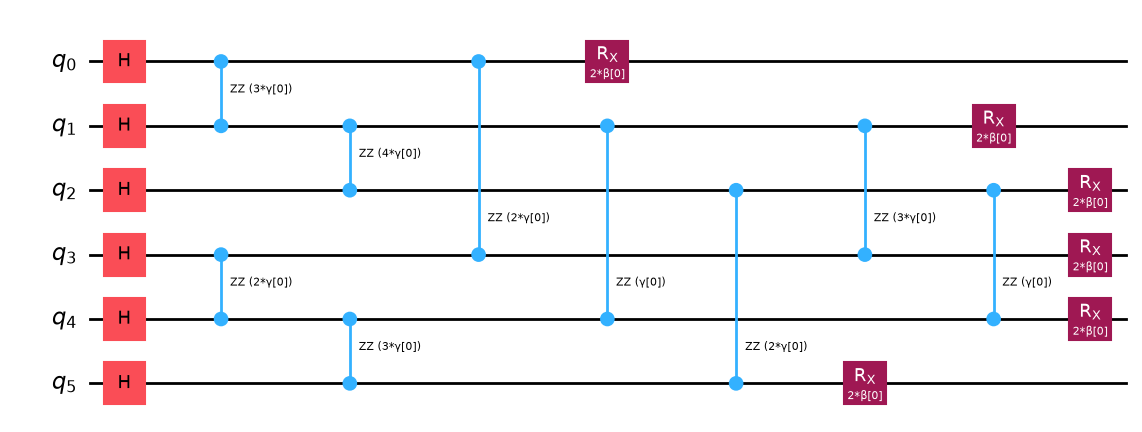

In [7]:
from qiskit.circuit.library import qaoa_ansatz

qaoa = qaoa_ansatz(cost, reps=1)
print(f"量子ビットの数: {qaoa.num_qubits}")
print(f"調整できるパラメーター: {list(qaoa.parameters)}")
qaoa.draw("mpl", fold=-1)

回路図の左端の H は、第2章で導入した H ゲートで、すべての割り当てを等しい確率で含む重ね合わせを作ります。その右には、隣り合う組ごとに、2つの量子ビットにまたがるゲート(`ZZ`)が1つずつ並びます。ゲートの角度には、組の重みが反映されています。右端の `Rx` は、1つの量子ビットだけにかかるゲートです。どのゲートが何をしているかは、この教材では扱いません。

回路には、$\beta$ と $\gamma$ という2つの**パラメーター**(回路の中の角度)があります。パラメーターの値によって、どの割り当てが出やすいかが変わります。

## 量子回路の実行

### パラメーターを調整する

回路のパラメーターを、$C$ の値が小さくなるように調整します。調整には、古典最適化(COBYLA)を使います。手順は次のとおりです。

1. パラメーターの値を決めて、回路から $C$ の値を計算する(ここでは量子計算をシミュレーターで行う)。
2. 古典の最適化の手法が、$C$ の値が小さくなる方向に、パラメーターの値を更新する。
3. 値が変わらなくなるまで、1と2を繰り返す。

量子計算と古典計算を何度も往復して、答えに近づけていく進め方です。最適化の結果は、パラメーターの初期値によって変わることがあるので、初期値を変えて10回調整し、最も $C$ の値が小さかったものを使います。初期値は、乱数のシードを固定して選びます。

In [8]:
from collections import Counter

import numpy as np
from scipy.optimize import minimize

def cost_value(circuit, x):
    """パラメーター x を入れた回路の出力について、C の値(測定結果ごとの値の平均)を計算する。"""
    return Statevector(circuit.assign_parameters(x)).expectation_value(cost).real


def optimize(circuit, seed, tries=10):
    """初期値を変えて tries 回パラメーターを調整する。C の値が最も小さかった結果と、全試行の結果を返す。"""
    rng = np.random.default_rng(seed)
    trials = [
        minimize(lambda x: cost_value(circuit, x), rng.uniform(0, np.pi, circuit.num_parameters), method="COBYLA")
        for _ in range(tries)
    ]
    return min(trials, key=lambda r: r.fun), trials


result, trials = optimize(qaoa, seed=12345)
print(f"C の値: {result.fun:.3f}")
print(f"重みの合計の平均(W/2 - C): {TOTAL_WEIGHT / 2 - result.fun:.3f}")

C の値: -3.625
重みの合計の平均(W/2 - C): 14.125


調整の結果、$C$ の値は $-3.625$ になりました。上の式から、重みの合計の平均は $21/2 - (-3.625) = 14.125$ です。$C$ の値は、回路を何度も測定したときの、測定結果ごとの値の平均を表します。そのため、重みの合計も、1つの割り当ての値ではなく、測定結果の平均として得られます。

10回の調整が、それぞれどの値で止まったかを見ます。

In [9]:
print("10回の調整で、最終的に止まった C の値")
for value, n in sorted(Counter(round(r.fun, 3) for r in trials).items()):
    print(f"  C = {value:>6.3f}(重みの合計の平均 {TOTAL_WEIGHT / 2 - value:.3f}): {n} 回")

10回の調整で、最終的に止まった C の値
  C = -3.625(重みの合計の平均 14.125): 3 回
  C = -2.118(重みの合計の平均 12.618): 2 回
  C = -1.972(重みの合計の平均 12.472): 5 回


10回のうち、$C = -3.625$ に達したのは3回だけでした。残りの7回は、$-2.118$ や $-1.972$ で止まっています。最適化の手法は、その近くでそれ以上良くならない値で止まり、それが最も良い値であるとは限りません。初期値を変えて何度も調整したのは、このためです。10回の中で最も良かった $-3.625$ も、これより良い値がないことが保証されているわけではありません。

### 測定して割り当てを受け取る

調整したパラメーターを回路に入れ、測定を加えて1000回実行します。

In [10]:
from qiskit.primitives import StatevectorSampler

SHOTS = 1000
measured = qaoa.assign_parameters(result.x).measure_all(inplace=False)
counts = StatevectorSampler(seed=12345).run([measured], shots=SHOTS).result()[0].data.meas.get_counts()

print("回数  重みの合計  割り当て")
for bitstring, n in Counter(counts).most_common(8):
    a = to_assignment(bitstring)
    mark = "  ← 最適" if a in best_assignments else ""
    print(f"{n:>4} {scores[a]:>11}  {describe(a)}{mark}")

hits = sum(n for b, n in counts.items() if to_assignment(b) in best_assignments)
print(f"\n最適な割り当てが出た回数: {hits} / {SHOTS} 回")

回数  重みの合計  割り当て
  91          17  A:後 B:前 C:後 D:前 E:後 F:前  ← 最適
  90          17  A:前 B:後 C:前 D:後 E:前 F:後  ← 最適
  66          16  A:前 B:後 C:前 D:前 E:後 F:前
  52          15  A:後 B:後 C:前 D:前 E:前 F:後
  50          16  A:後 B:前 C:後 D:後 E:後 F:前
  49          15  A:前 B:前 C:後 D:後 E:後 F:前
  46          16  A:後 B:前 C:後 D:後 E:前 F:後
  45          15  A:後 B:後 C:前 D:前 E:後 F:前

最適な割り当てが出た回数: 181 / 1000 回


1000回のうち、最も多く出た2つの割り当ては、どちらも最適な割り当て(重みの合計17)で、合わせて181回出ました。その次に多いのは、重みの合計が16や15の割り当てです。最適な割り当てが最も多く出ていますが、1000回の大部分は、最適でない割り当てです。

## 結果を解釈する

### 答えは確率の分布として返ってくる

QAOA の出力は、1つの答えではなく、割り当ての確率の分布です。64通りの割り当てを、重みの合計の値ごとにまとめて示します。測定の回数による偶然のばらつきを含まない理論値で示します。

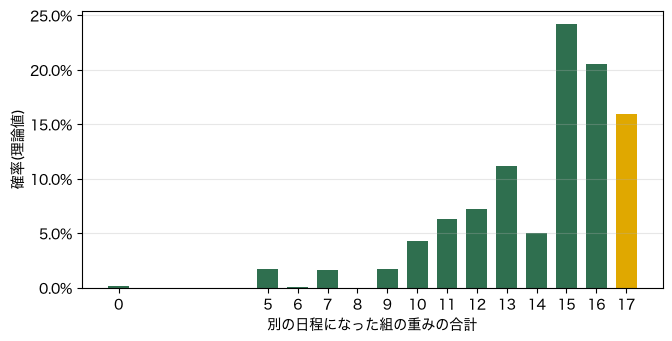

重みの合計  割り当ての数  棒の高さ  割り当て1つあたり
        17          2 通り    15.9%             8.0%
        16          4 通り    20.5%        4.4%〜5.9%
        15          6 通り    24.2%        2.9%〜4.8%


In [11]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter

# 日本語のラベルを表示するため、使える日本語フォントがあれば使う
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
japanese_fonts = [f for f in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic") if f in available_fonts]
plt.rcParams["font.family"] = japanese_fonts + ["sans-serif"]


def score_distribution(circuit, x):
    """回路の出力を、重みの合計の値ごとの確率にまとめる(状態ベクトルから計算する理論値)。"""
    dist = Counter()
    for bitstring, p in Statevector(circuit.assign_parameters(x)).probabilities_dict().items():
        dist[scores[to_assignment(bitstring)]] += p
    return dist


qaoa_dist = score_distribution(qaoa, result.x)

values = sorted(set(scores.values()))
colors = ["#e0a800" if v == best_score else "#2f6f4f" for v in values]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(values, [qaoa_dist[v] for v in values], 0.7, color=colors)
ax.set_xlabel("別の日程になった組の重みの合計")
ax.set_ylabel("確率(理論値)")
ax.set_xticks(values)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", alpha=0.3)
plt.show()

# 棒は、同じ重みの合計を持つ割り当ての確率を足したもの。割り当ての数と、1つあたりの確率を並べる
per_assignment = Statevector(qaoa.assign_parameters(result.x)).probabilities_dict()
print("重みの合計  割り当ての数  棒の高さ  割り当て1つあたり")
for v in sorted(values, reverse=True)[:3]:
    ps = [p for b, p in per_assignment.items() if scores[to_assignment(b)] == v]
    each = f"{min(ps):.1%}〜{max(ps):.1%}" if max(ps) - min(ps) > 5e-4 else f"{max(ps):.1%}"
    print(f"{v:>10} {len(ps):>10} 通り {sum(ps):>8.1%} {each:>16}")

確率は、15〜17の、重みの合計が大きい側に寄っていて、この3つの値で合わせて約61%です。最適な割り当て(17、黄色の棒)の確率は約15.9%です。

グラフでは15の棒が最も高くなっていますが、これは15の割り当てが最も出やすいという意味ではありません。棒は、同じ重みの合計を持つ割り当ての確率を足したもので、重みの合計が15の割り当ては6通り、17は2通りあります。割り当て1つあたりで比べると、最も確率が高いのは最適な割り当て(17)で、それぞれ約8.0%です。15の割り当ては、1つあたり約2.9〜4.8%です。測定で最も多く出た2つが、どちらも最適な割り当てだったことと一致します。

一方で、残りの約84%は最適でない割り当てです。重みの合計が10以下の割り当ても、合わせて約10%の確率で出ます。QAOA は、良い割り当てが出やすい分布を作りますが、最適な割り当てを確実に返すものではありません。

### 候補から割り当てを選ぶ

そのため、測定で得た割り当ては「候補」として扱い、それぞれの良し悪しを古典計算で評価して、最も良いものを選びます。この題材では、重みの合計を `cut_weight` で計算できます。1000回の測定に現れた候補から、重みの合計が最も大きい割り当てを選び、全探索で求めた答えと比べます。

In [12]:
candidates = {to_assignment(b) for b in counts}
chosen = max(candidates, key=cut_weight)

print(f"測定に現れた候補: {len(candidates)} 通り")
print(f"選んだ割り当て: {describe(chosen)}(重みの合計 {cut_weight(chosen)})")
print(f"全探索の答えと一致するか: {chosen in best_assignments}")

測定に現れた候補: 56 通り
選んだ割り当て: A:後 B:前 C:後 D:前 E:後 F:前(重みの合計 17)
全探索の答えと一致するか: True


1000回の測定に現れた候補から、重みの合計が17の割り当てを選べました。これは、全探索で求めた最適な割り当ての1つと一致します。

量子計算は割り当ての候補を返し、その中から良いものを選ぶのは古典計算の役割です。この章で扱った規模では全探索で答えが分かるので、選んだ割り当てが最適かを確かめられました。規模が大きく全探索ができない問題では、選んだ割り当てが最適かどうかは分かりません。

## まとめ

販促セールの日程の振り分けを例に、問題を量子計算で扱って結果を受け取るまでを、一通り実行しました。

この章の実行は、すべて誤りのない理想的なシミュレーター上のものです。同じ回路を実際の量子コンピューターで実行するには、回路を実機の制約に合わせる必要があり、結果も理想とは異なります。これらは、以降の章で扱います。

## 実行環境

このノートブックの実行に使ったライブラリのバージョンです。

In [13]:
import ast
import platform
from importlib.metadata import packages_distributions, version

# このノートブックが import している Qiskit 系のパッケージだけを表示する
used = set()
for source in In:
    try:
        nodes = ast.walk(ast.parse(source))
    except SyntaxError:  # ! や % で始まるセルは読み飛ばす
        continue
    for node in nodes:
        if isinstance(node, ast.Import):
            tops = [a.name.split(".")[0] for a in node.names]
        elif isinstance(node, ast.ImportFrom) and node.level == 0:
            tops = [node.module.split(".")[0]]
        else:
            continue
        for top in tops:
            if top.startswith("qiskit"):
                used.update(packages_distributions().get(top, []))

print(f"{'python':<24} {'.'.join(platform.python_version().split('.')[:2])}")
for name in sorted(used):
    print(f"{name:<24} {version(name)}")

python                   3.12
qiskit                   2.4.2
